# Solving CartPole-v1 with REINFORCE (policy gradient, `ptan`)

**Goal:** learn a policy `pi(a | s)` that keeps the pole balanced for 500 steps (the maximum in `CartPole-v1`).

**Pipeline:** play episodes with the current policy -> compute discounted returns -> policy-gradient update -> repeat.
After training, the notebook plots the learning curve, shows the agent live, and records an mp4.

## Importing Dependencies

torch is used to build the model and perform fast computation, ptan is used as a reinformcemnt library to abstrack some of the low level functionnalities such as performing the one step action in an environment. numpy is used for fast computation. Other dependencies hide some other implementations

In [1]:
import ptan 
import gymnasium as gym

import torch
from torch import nn


import numpy as np

from lib.model import CartePoleNet
from lib.commons import *

## 3. Environment
`rgb_array` render mode lets us grab frames later for display/recording. It slows training a bit; use `render_mode=None` if you only train.
`reset()` below just shows what an observation looks like: `[cart position, cart velocity, pole angle, pole angular velocity]`.

In [2]:
env = gym.make("CartPole-v1", render_mode="rgb_array")

In [3]:
obs, _ = env.reset()

In [4]:
print(obs)

[-0.02763801  0.03111626 -0.03085281 -0.018744  ]


## 4. Policy network and optimiser

`CartePoleNet` (in `lib/model.py`) is a small MLP: `state (4) -> 128 -> ReLU -> logits (2)`.
It outputs **raw logits**, not probabilities. The agent applies softmax when sampling, and the loss uses `log_softmax`.
Hyper-parameters (`GAMMA`, `LEARNING_RATE`, `EPISODES_TO_TRAIN`), `device`, `writer` and `compte_qvals` come from `lib/commons.py`.

In [5]:
obs_dim = None
action_space = env.action_space.n

if hasattr(env.observation_space, "shape") and env.observation_space.shape is not None:
    obs_dim = env.observation_space.shape[0]
    print(f"observation dim is {obs_dim}")
else:
    obs_dim = env.observation_space.n

net = CartePoleNet(action_space, obs_dim).to(device)  

optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)

observation dim is 4


## 5. Agent and experience source

> **Run order matters.** `agent` and `exp_source` hold a *reference* to `net`.
> If you re-run the `net` cell you must re-run the agent, experience-source and state cells too
> (or use *Restart & Run All*), otherwise you train a different network from the one that is acting.

- `ProbabilityActionSelector` samples an action from the probability vector.
- `PolicyAgent(..., apply_softmax=True)` turns the net's logits into probabilities and samples.
- `ExperienceSourceFirstLast(steps_count=1)` yields one transition per step; `last_state is None` marks the **end of an episode**.

In [6]:
action_selector = ptan.actions.ProbabilityActionSelector()

In [7]:
agent = ptan.agent.PolicyAgent(net, action_selector, device, apply_softmax=True)

In [8]:
exp_source = ptan.experience.ExperienceSourceFirstLast(env, agent, steps_count=1, gamma=GAMMA)    

## 6. Training state
Accumulators for the current episode, the current batch, and logging. **Re-run this cell before restarting training**,
because an interrupted run leaves a dead iterator and half-filled lists.

In [9]:
total_rewards = []
mean_rewards = []
done_episodes = 0
batch_episodes = 0
batch_states, batch_actions, batch_qvals = [], [], []
cur_rewards = []
cur_states = []
cur_actions = []
losses = []
step_idx=0

# Create an iterator over your experience source
exp_source_iter = iter(exp_source)

## 7. Training loop (REINFORCE)

Per step: store `(state, action, reward)`. At episode end, convert rewards to discounted returns `G_t = r_t + gamma * G_(t+1)` and move them into the batch.
After `EPISODES_TO_TRAIN` episodes:
1. standardise the returns (acts as a baseline and stabilises the gradient),
2. `loss = -mean(log pi(a|s) * G)`, which raises the probability of actions that led to high return,
3. one Adam step, then clear the batch and log to TensorBoard (`tensorboard --logdir runs`).

Stops when the 100-episode mean reward exceeds 450. The loss is **not** a progress signal in REINFORCE; watch the mean reward.

In [10]:
for exp in exp_source_iter:
    cur_states.append(np.array(exp.state))
    cur_actions.append(exp.action)
    cur_rewards.append(exp.reward)

    if exp.last_state is None:
        total_rewards.append(sum(cur_rewards))
        batch_qvals.extend(compte_qvals(cur_rewards, GAMMA))
        batch_states.extend(cur_states)
        batch_actions.extend(cur_actions)
        cur_states.clear()
        cur_actions.clear()
        cur_rewards.clear()
        done_episodes += 1
    
    # Optional: collect a sample batch of 4 steps and break to inspect
    if done_episodes == EPISODES_TO_TRAIN:
        batch_states_t = torch.as_tensor(batch_states).to(device)
        batch_actions_t = torch.as_tensor(batch_actions).to(device)
        batch_qvals_t = torch.as_tensor(batch_qvals).to(device)

        # Standardize batch_qvals_t for numerical stability:
        batch_qvals_t = (batch_qvals_t - batch_qvals_t.mean()) / (batch_qvals_t.std() + 1e-8)
        
        logits = net(batch_states_t)

        log_probs = torch.nn.functional.log_softmax(logits, dim=1)

        action_log_probs = log_probs.gather(1, batch_actions_t.unsqueeze(1)).squeeze(1)

        loss = - torch.mean(action_log_probs * batch_qvals_t)
        losses.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        done_episodes = 0
        batch_states.clear()
        batch_actions.clear()
        batch_qvals.clear()

        mean_r = np.mean(total_rewards[-100:])
        step_idx += 1
        writer.add_scalar("loss/train", loss.item(), step_idx)
        writer.add_scalar("mean_r/train", mean_r, step_idx)
        
        mean_rewards.append(mean_r)
        
        print(f"loss {loss}, Mean reward {mean_r}")
    
        if mean_r > 450:
            break
writer.close()

/var/folders/qc/lqtqnzks33vc7w73hnbk81gm0000gn/T/ipykernel_85180/1926227608.py:18: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:277.)
  batch_states_t = torch.as_tensor(batch_states).to(device)


loss 0.0007529038703069091, Mean reward 16.25
loss 0.11128216981887817, Mean reward 13.5
loss 0.11068238317966461, Mean reward 13.166666666666666
loss 0.19429954886436462, Mean reward 13.0
loss 0.009339774027466774, Mean reward 12.75
loss 0.019229412078857422, Mean reward 13.333333333333334
loss 0.007559632882475853, Mean reward 15.142857142857142
loss -0.005650680977851152, Mean reward 16.625
loss -0.014773753471672535, Mean reward 16.88888888888889
loss -0.01067298837006092, Mean reward 21.15
loss -0.006357024889439344, Mean reward 21.772727272727273
loss -0.013622308149933815, Mean reward 23.6875
loss 0.008555247448384762, Mean reward 26.057692307692307
loss -0.004972060676664114, Mean reward 26.660714285714285
loss -0.006516246125102043, Mean reward 28.216666666666665
loss -0.02445172145962715, Mean reward 29.5625
loss 0.00987742468714714, Mean reward 31.941176470588236
loss 0.026550348848104477, Mean reward 32.333333333333336
loss 0.009885822422802448, Mean reward 33.2368421052631

## 8. Learning curve
Per-episode reward (faint) and the 100-episode moving mean the loop uses for its stopping rule.

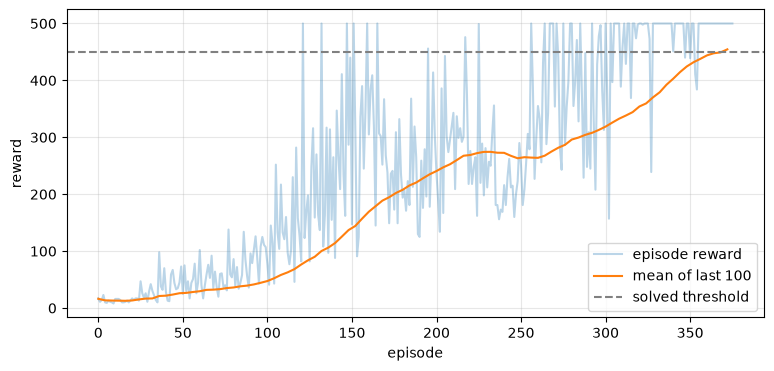

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(total_rewards, alpha=0.3, label="episode reward")
# mean_rewards has one point per training batch (EPISODES_TO_TRAIN episodes)
ax.plot(np.arange(len(mean_rewards)) * EPISODES_TO_TRAIN, mean_rewards, label="mean of last 100")
ax.axhline(450, ls="--", c="gray", label="solved threshold")
ax.set_xlabel("episode"); ax.set_ylabel("reward"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 9. Watching and recording the trained agent

`play_episode` runs the trained policy in a **fresh** environment (so training state is untouched), under `torch.no_grad()`.
- `greedy=True` takes `argmax` (best action); `greedy=False` samples like during training.
- `on_frame` is called with each RGB frame, used below for live display and video writing.

In [12]:
import os, time
import imageio
from PIL import Image
from IPython.display import display, clear_output, Video

def play_episode(net, device, greedy=True, seed=None, on_frame=None, max_steps=500):
    """Run one episode with the trained policy and return its total reward."""
    eval_env = gym.make("CartPole-v1", render_mode="rgb_array")
    obs, _ = eval_env.reset(seed=seed)
    net.eval()
    total = 0.0
    try:
        for _ in range(max_steps):
            if on_frame is not None:
                on_frame(eval_env.render())
            with torch.no_grad():
                logits = net(torch.as_tensor(obs, dtype=torch.float32, device=device).unsqueeze(0))
                probs = torch.softmax(logits, dim=1)
            if greedy:
                action = int(probs.argmax(dim=1).item())
            else:
                action = int(torch.multinomial(probs, 1).item())
            obs, reward, terminated, truncated, _ = eval_env.step(action)
            total += reward
            if terminated or truncated:
                break
    finally:
        eval_env.close()
        net.train()
    return total

### 9.1 Score over several evaluation episodes

In [13]:
greedy_scores = [play_episode(net, device, greedy=True, seed=s) for s in range(10)]
sample_scores = [play_episode(net, device, greedy=False, seed=s) for s in range(10)]
print(f"greedy  : mean {np.mean(greedy_scores):.1f}  min {min(greedy_scores):.0f}  max {max(greedy_scores):.0f}")
print(f"sampled : mean {np.mean(sample_scores):.1f}  min {min(sample_scores):.0f}  max {max(sample_scores):.0f}")

greedy  : mean 497.6  min 476  max 500
sampled : mean 500.0  min 500  max 500


### 9.2 Live display in the notebook
Redraws one image in place (about 30 fps). Stop it with the interrupt button if needed.

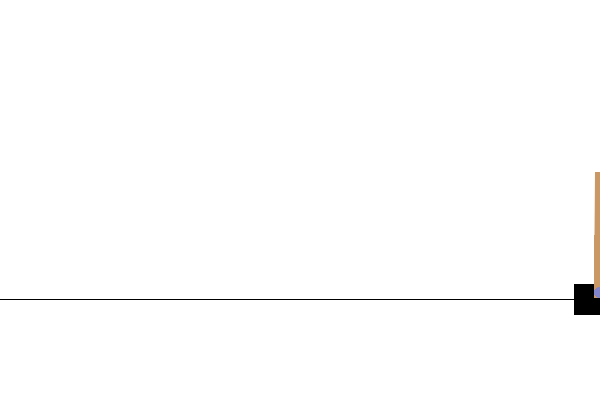

episode reward: 476.0


In [14]:
def show_frame(frame, fps=30):
    clear_output(wait=True)
    display(Image.fromarray(frame))
    time.sleep(1 / fps)

score = play_episode(net, device, greedy=True, seed=0, on_frame=show_frame)
print("episode reward:", score)

### 9.3 Record an mp4
Frames are streamed straight to disk (no big in-memory list). The file is saved to `videos/` next to this notebook and shown inline.

In [15]:
os.makedirs("videos", exist_ok=True)
video_path = "videos/cartpole_reinforce.mp4"

# macro_block_size=1 keeps the native 600x400 size (no resize warning)
with imageio.get_writer(video_path, fps=30, macro_block_size=1) as video_writer:
    score = play_episode(net, device, greedy=True, seed=0, on_frame=video_writer.append_data)

print(f"recorded episode reward: {score} -> {video_path}")
Video(video_path, embed=True, width=600)

recorded episode reward: 476.0 -> videos/cartpole_reinforce.mp4
